In [18]:
import numpy as np
import importlib
import path_planning

In [22]:
importlib.reload(path_planning)

<module 'path_planning' from '/Users/shash/Documents/Projects/SatelliteRendezvous/algorithm_testing/path_planning.py'>

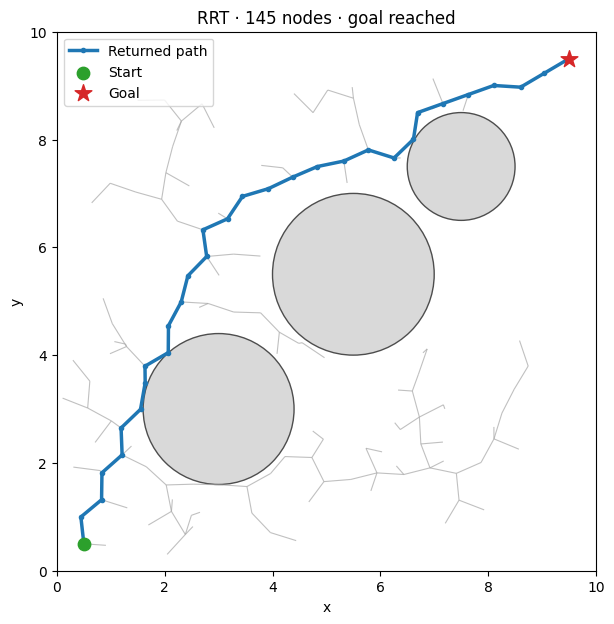

In [23]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle

start = (0.5, 0.5)
goal = (9.5, 9.5)
bounds = ((0, 10), (0, 10))
obstacles = [
    (3.0, 3.0, 1.4),
    (5.5, 5.5, 1.5),
    (7.5, 7.5, 1.0),
]

path, nodes = path_planning.plan_rrt(
    start, goal, bounds, obstacles,
    step_size=0.5,
    goal_tol=0.4,
    seed=42,
)

fig, ax = plt.subplots(figsize=(7, 7))

edges = [
    [node.parent.state, node.state]
    for node in nodes
    if node.parent is not None
]
ax.add_collection(
    LineCollection(edges, colors="0.65", linewidths=0.8, alpha=0.7)
)

for ox, oy, radius in obstacles:
    ax.add_patch(Circle((ox, oy), radius, facecolor="0.85", edgecolor="0.3"))

if path is not None:
    points = np.asarray(path)
    ax.plot(
        points[:, 0], points[:, 1],
        color="tab:blue", linewidth=2.5, marker=".", label="Returned path",
        zorder=3,
    )

ax.scatter(*start, color="tab:green", s=80, label="Start", zorder=4)
ax.scatter(*goal, color="tab:red", marker="*", s=160, label="Goal", zorder=4)
ax.set(
    xlim=bounds[0],
    ylim=bounds[1],
    xlabel="x",
    ylabel="y",
    title=f"RRT · {len(nodes)} nodes · {'goal reached' if path is not None else 'no path found'}",
)
ax.set_aspect("equal")
ax.legend()
plt.show()